# Visión por Computadora
## Clase 7 — Entrenamiento, regularización y evaluación
### Unidad 2 · Redes convolucionales y modelos avanzados

**Laboratorio práctico (con Jupyter).** La clase pasada tu CNN llegó a cerca de 90 % sobre la ropa de FashionMNIST y le ganó al MLP. Pero tuvo todo a favor, porque le dimos **60 000 fotos** y la paramos a las 5 épocas, así que nunca la vimos hacer trampa.

Hoy le quitamos esa ventaja. Le damos **solo 800 fotos**, una red con memoria de sobra y muchas épocas, y la vamos a ver **memorizar en vez de aprender**. A eso se le llama **sobreajuste** (*overfitting*), y es el problema que vas a encontrar en casi cualquier proyecto real, donde rara vez tienes miles de ejemplos.

En este laboratorio vas a:

1. ver el sobreajuste con un ejemplo diminuto de 8 puntos, antes de tocar una red,
2. preparar **tres conjuntos de datos** con papeles distintos (entrenamiento, validación y prueba),
3. **provocar el sobreajuste a propósito** y reconocerlo en las curvas,
4. curarlo por tres frentes, los **datos** (aumento), el **modelo** (dropout y weight decay) y el **tiempo** (early stopping),
5. y **evaluar de verdad** con la exactitud en prueba y la **matriz de confusión**.

**Cómo trabajar en Colab:** ejecuta cada celda con `Shift + Enter`, en orden. No necesitas instalar nada. Hoy entrenamos cuatro redes, así que conviene activar la GPU (*Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4*). Sin GPU también funciona, solo que tarda más. Antes de correr cada celda, intenta **predecir** qué va a pasar.

# Se trabajara con Jupyter

---

## Parte 0 — Preparar el entorno

Traemos las librerías. Son casi las mismas de la Clase 6, más dos pequeñas: `copy`, para guardar una copia del mejor modelo, y `time`, para medir cuánto tarda cada entrenamiento.

In [1]:
# ----------------------------------------------------------------------------
# Cada 'import' trae una caja de herramientas ya hecha.
# ----------------------------------------------------------------------------
import copy                            # copy: para guardar una copia exacta del mejor modelo
import time                            # time: para cronometrar cada entrenamiento
import numpy as np                     # NumPy: tablas de números
import matplotlib.pyplot as plt        # Matplotlib: dibujar imágenes y curvas
import torch                           # PyTorch: la librería de redes neuronales
import torch.nn as nn                  # nn: las piezas para armar redes
import torchvision                     # torchvision: datasets de imágenes
from torchvision import transforms     # transforms: preparar (y hoy, también deformar) imágenes

# Semilla: hace que el azar salga siempre igual, para que todos obtengamos curvas parecidas.
torch.manual_seed(0)

# GPU si está activada; si no, el procesador normal (CPU).
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usaremos:", device)

# Los nombres de las 10 clases de FashionMNIST, en el orden del dataset (0 a 9).
CLASES = ["camiseta", "pantalón", "suéter", "vestido", "abrigo",
          "sandalia", "camisa", "zapatilla", "bolso", "botín"]

Usaremos: cpu


---

## Parte 1 — Primero lo pequeño: memorizar contra aprender con 8 puntos

Regla del curso: **primero lo pequeño, después lo real.** Antes de cualquier red, veamos el sobreajuste en su versión más simple.

Tenemos una regla escondida (una curva suave) y solo **8 puntos** medidos con un poco de ruido, como pasa con cualquier medición real. Le pedimos a tres "modelos" que aprendan la regla a partir de esos 8 puntos:

- una **recta** (grado 1), un modelo muy simple,
- una **curva de grado 3**, un modelo de tamaño razonable,
- una **curva de grado 7**, un modelo con tanta flexibilidad que puede pasar exactamente por los 8 puntos.

Después medimos cada modelo en dos lugares: sobre los 8 puntos que vio (**entrenamiento**) y sobre **100 puntos nuevos** que nunca vio.

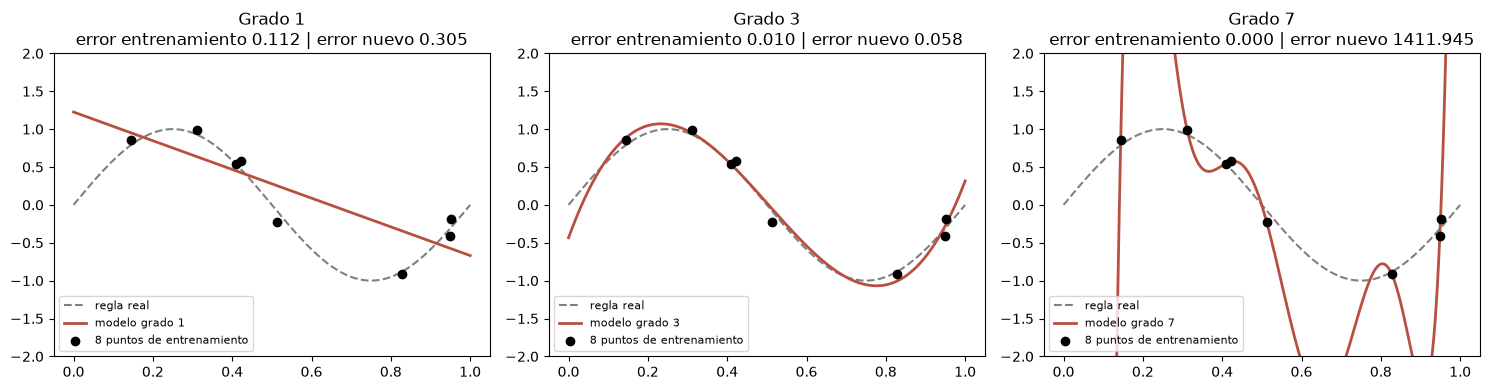

In [2]:
rng = np.random.default_rng(1)                     # generador de azar con semilla fija

def regla(x):                                      # la "verdad" escondida que queremos aprender
    return np.sin(2 * np.pi * x)                   # una onda suave

# Solo 8 puntos para entrenar, medidos con ruido (como una medición real)
x_train = np.sort(rng.uniform(0, 1, 8))            # 8 posiciones al azar entre 0 y 1
y_train = regla(x_train) + rng.normal(0, 0.2, 8)   # su valor real + un poco de ruido

# 100 puntos NUEVOS de la misma regla: el "examen" que el modelo nunca vio
x_nuevo = rng.uniform(0, 1, 100)
y_nuevo = regla(x_nuevo) + rng.normal(0, 0.2, 100)

x_dibujo = np.linspace(0, 1, 300)                  # muchos puntos seguidos, solo para dibujar curvas

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, grado in zip(axs, [1, 3, 7]):              # probamos tres modelos de flexibilidad creciente
    coef = np.polyfit(x_train, y_train, grado)     # "entrenar": ajustar la curva a los 8 puntos
    err_train = np.mean((np.polyval(coef, x_train) - y_train) ** 2)  # error en lo que vio
    err_nuevo = np.mean((np.polyval(coef, x_nuevo) - y_nuevo) ** 2)  # error en lo nuevo

    ax.plot(x_dibujo, regla(x_dibujo), "--", color="gray", label="regla real")
    ax.plot(x_dibujo, np.polyval(coef, x_dibujo), color="#B85042", lw=2, label=f"modelo grado {grado}")
    ax.scatter(x_train, y_train, color="black", zorder=3, label="8 puntos de entrenamiento")
    ax.set_ylim(-2, 2)
    ax.set_title(f"Grado {grado}\nerror entrenamiento {err_train:.3f} | error nuevo {err_nuevo:.3f}")
    ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

**Léelo así, de izquierda a derecha:**

| Modelo | Error en lo que vio | Error en lo nuevo | Diagnóstico |
|---|---|---|---|
| Grado 1 (recta) | alto | alto | **Subajuste**: es tan simple que ni siquiera aprende lo que tiene delante |
| Grado 3 | bajo | bajo | **Buen ajuste**: capta la forma de la regla y funciona con datos nuevos |
| Grado 7 | casi **cero** | **enorme** | **Sobreajuste**: pasa exacto por los 8 puntos, ruido incluido, y entre ellos inventa ondas absurdas |

El grado 7 es el **estudiante que memoriza**: saca nota perfecta en lo que vio y se hunde en el examen. Fíjate en la trampa: si solo miraras el error de entrenamiento, el grado 7 parecería el mejor.

Ahora vamos a provocar exactamente esto con una red de verdad: una CNN con más de 400 000 parámetros (mucha flexibilidad) y solo 800 fotos (pocos puntos).

---

## Parte 2 — Los datos en modo difícil: tres conjuntos, tres papeles

Usamos FashionMNIST, igual que en la Clase 6, para que la comparación sea limpia. La novedad es cómo repartimos los datos:

- **Entrenamiento (`train`, 800 fotos):** donde la red estudia y ajusta sus pesos. Son pocas a propósito: así nace el sobreajuste.
- **Validación (`val`, 2000 fotos):** un examen sorpresa que le tomamos al final de **cada época**. La red **nunca** aprende de estas fotos; solo nos dicen si está generalizando. Con ellas tomaremos decisiones, como cuándo parar.
- **Prueba (`test`, 10 000 fotos):** el juez final. Se mira **una sola vez**, al terminar, para dar el veredicto.

Las fotos de validación salen del mismo conjunto de entrenamiento de FashionMNIST, pero son **otras** fotos, que la red no ve al estudiar.

In [4]:
N_TRAIN = 800       # pocas fotos a propósito: aquí nace el sobreajuste
N_VAL   = 2000      # fotos de validación (el examen sorpresa de cada época)
BATCH   = 64        # tamaño de lote, igual que en la Clase 6

tfm = transforms.ToTensor()   # receta básica: pasar cada imagen a tensor con valores 0..1

# Descargamos FashionMNIST (60 000 de entrenamiento y 10 000 de prueba)
full_train = torchvision.datasets.FashionMNIST(root="./data", train=True,  download=True, transform=tfm)
test_data  = torchvision.datasets.FashionMNIST(root="./data", train=False, download=True, transform=tfm)

# Barajamos los índices 0..59999 con una semilla fija, para que todos tengamos las MISMAS fotos
g = torch.Generator().manual_seed(0)              # un generador de azar propio, con semilla 0
perm = torch.randperm(len(full_train), generator=g)   # los 60 000 índices, desordenados
idx_train = perm[:N_TRAIN]                        # las primeras 800 -> entrenamiento
idx_val   = perm[N_TRAIN:N_TRAIN + N_VAL]         # las 2000 siguientes -> validación (sin repetir)

# Subset = "un pedazo del dataset": solo las fotos cuyos índices le pasamos
train_small = torch.utils.data.Subset(full_train, idx_train)
val_data    = torch.utils.data.Subset(full_train, idx_val)

# DataLoaders: entregan las fotos de a lotes
train_loader      = torch.utils.data.DataLoader(train_small, batch_size=BATCH, shuffle=True)  # para ESTUDIAR (barajado)
train_eval_loader = torch.utils.data.DataLoader(train_small, batch_size=256)   # para MEDIR el train (sin barajar)
val_loader        = torch.utils.data.DataLoader(val_data,    batch_size=256)   # para MEDIR la validación
test_loader       = torch.utils.data.DataLoader(test_data,   batch_size=256)   # para el veredicto final

print(f"Entrenamiento: {len(train_small):>6} fotos   <- deliberadamente pocas")
print(f"Validación:    {len(val_data):>6} fotos   <- examen sorpresa de cada época")
print(f"Prueba:        {len(test_data):>6} fotos   <- juez final, se mira una vez")

Entrenamiento:    800 fotos   <- deliberadamente pocas
Validación:      2000 fotos   <- examen sorpresa de cada época
Prueba:         10000 fotos   <- juez final, se mira una vez


**¿Por qué dos loaders para las mismas 800 fotos?** `train_loader` es el que usa la red para **estudiar**: baraja las fotos y, más adelante, las deformará con aumento de datos. `train_eval_loader` sirve solo para **medir** cuánto acierta sobre esas mismas fotos, sin barajar ni deformar. Así comparamos train contra validación en igualdad de condiciones.

Ahora miremos qué tocó en esas 800 fotos. Con tan pocas, conviene revisar que las 10 clases estén representadas.

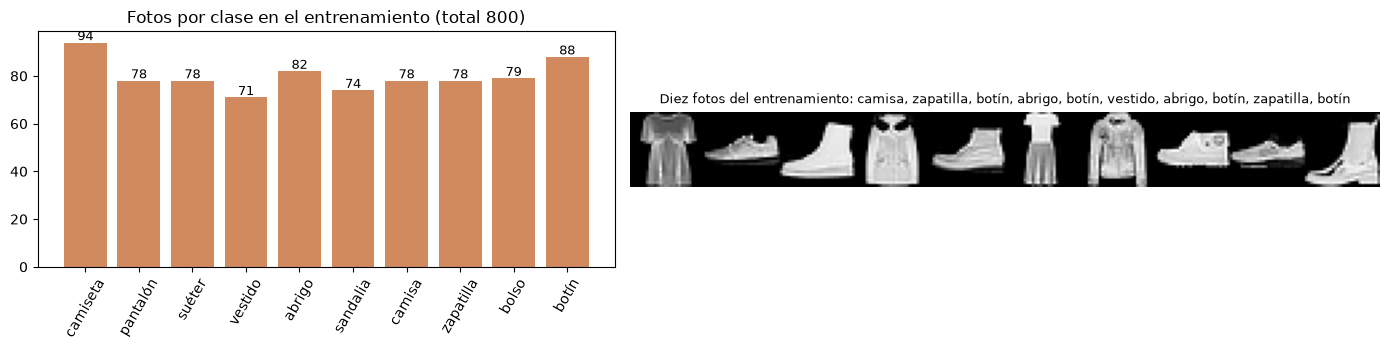

In [5]:
# ¿Cuántas fotos de cada clase quedaron en el entrenamiento?
etiquetas_train = full_train.targets[idx_train]          # la clase (0..9) de cada una de las 800
conteo = np.bincount(etiquetas_train.numpy(), minlength=10)   # cuántas hay de cada clase

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})

# Izquierda: barras con el conteo por clase
a.bar(CLASES, conteo, color="#D08A5E")
a.set_title(f"Fotos por clase en el entrenamiento (total {N_TRAIN})")
a.tick_params(axis="x", rotation=60)
for i, c in enumerate(conteo):
    a.text(i, c + 1, str(c), ha="center", fontsize=9)      # el número encima de cada barra

# Derecha: una tira con 10 fotos del entrenamiento
b.axis("off")
tira = torch.cat([train_small[i][0][0] for i in range(10)], dim=1)   # 10 fotos pegadas en fila
b.imshow(tira, cmap="gray")
b.set_title("Diez fotos del entrenamiento: " + ", ".join(CLASES[full_train.targets[idx_train[i]]] for i in range(10)), fontsize=9)
plt.tight_layout(); plt.show()

Unas 80 fotos por clase. Para una persona es suficiente para entender qué es un bolso; para una red con cientos de miles de parámetros es poquísimo, y ahí está la tentación de memorizar.

---

## Parte 3 — Una red con memoria de sobra

Partimos de la CNN de la Clase 6 y la hacemos **más grande a propósito**: más filtros (32 y 64 en vez de 16 y 32) y una capa oculta de 128 neuronas antes de decidir. Eso le da muchísima capacidad, la suficiente para aprenderse de memoria 800 fotos.

La red recibe un parámetro, `dropout`. Con `dropout=0.0` no tiene ninguna defensa. Más adelante lo subiremos como una de las curas.

In [7]:
class CNN(nn.Module):                         # nuestra red; hereda de nn.Module, como en la Clase 6
    def __init__(self, dropout=0.0):          # 'dropout' = qué fracción de neuronas apagar (0 = ninguna)
        super().__init__()                    # arranca la maquinaria interna de PyTorch

        # --- BLOQUE QUE MIRA: mismo esquema que la Clase 6, con más filtros ---
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),   # 1 canal de entrada -> 32 mapas; filtro 3x3 (28x28 se mantiene)
            nn.ReLU(),                        # apaga lo negativo
            nn.MaxPool2d(2),                  # 28x28 -> 14x14
            nn.Conv2d(32, 64, 3, padding=1),  # 32 mapas -> 64 mapas
            nn.ReLU(),
            nn.MaxPool2d(2),                  # 14x14 -> 7x7
        )

        # --- BLOQUE QUE DECIDE: ahora con una capa oculta de 128 neuronas ---
        self.classifier = nn.Sequential(
            nn.Flatten(),                     # 64 mapas de 7x7 -> una fila de 3136 números
            nn.Linear(64 * 7 * 7, 128),       # 3136 -> 128: aquí está casi toda la "memoria" de la red
            nn.ReLU(),
            nn.Dropout(dropout),              # con dropout=0.0 no apaga nada (red sin defensa)
            nn.Linear(128, 10),               # 128 -> 10, una salida por clase
        )

    def forward(self, x):                     # el camino de una imagen por la red
        return self.classifier(self.features(x))   # primero mira, después decide

# Creamos una red de prueba solo para contar sus parámetros
red_prueba = CNN()
n_params = sum(p.numel() for p in red_prueba.parameters())
print(f"Parámetros de la red:          {n_params:,}")
print(f"Fotos de entrenamiento:        {N_TRAIN:,}")
print(f"Parámetros por cada foto:      {n_params / N_TRAIN:,.0f}")
print("(La CNN de la Clase 6 tenía 20,490 parámetros y 60,000 fotos: menos de 1 parámetro por foto.)")

Parámetros de la red:          421,642
Fotos de entrenamiento:        800
Parámetros por cada foto:      527
(La CNN de la Clase 6 tenía 20,490 parámetros y 60,000 fotos: menos de 1 parámetro por foto.)


**Más de 500 parámetros por cada foto.** En la Clase 6 la proporción era al revés: muchas más fotos que parámetros. Hoy la red tiene tanta capacidad que le sobra para aprenderse cada foto de memoria, con sus detalles irrelevantes incluidos. Es el polinomio de grado 7 de la Parte 1, en grande.

---

## Parte 4 — El motor de entrenamiento, ahora con validación

Hoy entrenamos cuatro redes, así que guardamos el loop de la Clase 6 dentro de una función reutilizable. Tiene tres novedades, y las tres son el corazón de la clase:

1. Al final de **cada época** mide la red sobre el entrenamiento **y** sobre la validación, y guarda los cuatro números (pérdida y exactitud de cada uno) en un **historial**. Con ese historial dibujaremos las curvas.
2. Acepta `weight_decay`, uno de los frenos que veremos en la Parte 7.
3. Acepta `paciencia`, para el **early stopping** de la Parte 8. Mientras valga `None`, está apagado.

Primero, la función que **mide** sin entrenar. Es la misma idea de la Clase 6.

In [8]:
def evaluar(model, loader):
    """Mide la red sobre un loader y devuelve (pérdida promedio, exactitud). No entrena."""
    criterio = nn.CrossEntropyLoss()           # la misma pérdida de siempre
    model.eval()                               # modo evaluación: apaga el dropout
    total, aciertos, perdida = 0, 0, 0.0
    with torch.no_grad():                      # sin gradientes: solo medimos, va más rápido
        for X, y in loader:                    # recorremos los lotes
            X, y = X.to(device), y.to(device)  # al mismo dispositivo que la red
            salida = model(X)                  # la red predice
            perdida += criterio(salida, y).item() * len(y)        # sumamos la pérdida del lote
            aciertos += (salida.argmax(1) == y).sum().item()      # contamos los aciertos
            total += len(y)                    # contamos cuántas fotos llevamos
    return perdida / total, aciertos / total  # promedios sobre todas las fotos

Ahora el motor. Lee los comentarios de arriba abajo: los cinco pasos del loop son exactamente los de la Clase 6; lo nuevo está **después** del loop de lotes.

In [9]:
def entrenar(model, loader_train, epocas=50, lr=1e-3, weight_decay=0.0, paciencia=None):
    """Entrena 'model' y devuelve su historial época por época.
    - weight_decay: freno que empuja los pesos a valores pequeños (0 = sin freno)
    - paciencia: épocas sin mejorar antes de parar (None = early stopping apagado)"""
    model = model.to(device)                                   # la red al dispositivo
    opt = torch.optim.Adam(model.parameters(), lr=lr,
                           weight_decay=weight_decay)          # el optimizador, con el freno opcional
    criterio = nn.CrossEntropyLoss()
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}   # el historial

    mejor_val = float("inf")      # la mejor pérdida de validación vista hasta ahora
    mejor_estado = None           # una copia de la red en ese mejor momento
    sin_mejora = 0                # cuántas épocas seguidas lleva sin mejorar
    inicio = time.time()

    for ep in range(1, epocas + 1):
        # ---- ESTUDIAR: los cinco pasos de la Clase 6, lote por lote ----
        model.train()                                          # modo entrenamiento (dropout activo)
        for X, y in loader_train:
            X, y = X.to(device), y.to(device)
            opt.zero_grad()                                    # 1) borrar gradientes viejos
            perdida = criterio(model(X), y)                    # 2) predecir y 3) medir el error
            perdida.backward()                                 # 4) calcular gradientes
            opt.step()                                         # 5) ajustar los pesos

        # ---- NOVEDAD 1: medir train y validación al cerrar la época ----
        tl, ta = evaluar(model, train_eval_loader)             # ¿cuánto acierta en lo que estudió?
        vl, va = evaluar(model, val_loader)                    # ¿y en el examen sorpresa?
        hist["train_loss"].append(tl); hist["train_acc"].append(ta)
        hist["val_loss"].append(vl);   hist["val_acc"].append(va)
        if ep == 1 or ep % 10 == 0:                            # imprimimos cada 10 épocas
            print(f"  época {ep:3d} | train {ta*100:5.1f}%  val {va*100:5.1f}%  "
                  f"| brecha {(ta-va)*100:+5.1f} pts | pérdida val {vl:.3f}")

        # ---- NOVEDAD 3: early stopping (solo si le dimos paciencia) ----
        if paciencia is not None:
            if vl < mejor_val:                                 # ¿mejoró la pérdida de validación?
                mejor_val = vl                                 # sí: anotamos el nuevo récord
                mejor_estado = copy.deepcopy(model.state_dict())   # guardamos una copia de la red
                hist["mejor_epoca"] = ep
                sin_mejora = 0                                 # y reiniciamos el contador
            else:
                sin_mejora += 1                                # no mejoró: una época más de espera
                if sin_mejora >= paciencia:                    # se acabó la paciencia
                    print(f"  -> Early stopping en la época {ep}: lleva {paciencia} épocas sin mejorar.")
                    hist["epoca_parada"] = ep
                    break

    if mejor_estado is not None:                               # si usamos early stopping...
        model.load_state_dict(mejor_estado)                    # ...nos quedamos con la MEJOR red, no la última
        print(f"  -> Recuperamos la red de la época {hist['mejor_epoca']}, la mejor en validación.")
    print(f"  Tiempo: {time.time() - inicio:.0f} s")
    return hist

Por último, una función para **dibujar** las curvas que vamos a leer toda la clase: a la izquierda la pérdida, a la derecha la exactitud, con train y validación juntas para que se vea la **brecha** entre ellas.

In [10]:
def curvas(hist, titulo, marcar=None):
    """Dibuja pérdida y exactitud de train y validación, lado a lado."""
    ep = range(1, len(hist["train_loss"]) + 1)                 # eje x: 1, 2, 3, ... épocas
    fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4))

    a.plot(ep, hist["train_loss"], color="#B85042", label="entrenamiento")
    a.plot(ep, hist["val_loss"], "--", color="#2E2A26", label="validación")
    a.set_title("Pérdida (más bajo = mejor)"); a.set_xlabel("época"); a.grid(alpha=0.3)

    b.plot(ep, [v*100 for v in hist["train_acc"]], color="#B85042", label="entrenamiento")
    b.plot(ep, [v*100 for v in hist["val_acc"]], "--", color="#2E2A26", label="validación")
    b.fill_between(ep, [v*100 for v in hist["val_acc"]], [v*100 for v in hist["train_acc"]],
                   color="#D08A5E", alpha=0.25, label="brecha")   # sombreamos la brecha
    b.set_title("Exactitud % (más alto = mejor)"); b.set_xlabel("época"); b.grid(alpha=0.3)

    if marcar:                                                 # una línea vertical en una época especial
        for ax in (a, b):
            ax.axvline(marcar, color="#6E6660", ls=":", lw=2)
    a.legend(); b.legend(loc="lower right")
    fig.suptitle(titulo, fontsize=13)
    plt.tight_layout(); plt.show()

    ta, va = hist["train_acc"][-1], hist["val_acc"][-1]
    print(f"Al final: train {ta*100:.1f}% | validación {va*100:.1f}% | brecha {(ta-va)*100:.1f} puntos")

---

## Parte 5 — Provocamos el sobreajuste a propósito

El experimento central de la clase. Tomamos la red grande **sin ninguna defensa** (`dropout=0.0`, sin weight decay, sin aumento) y la dejamos estudiar las 800 fotos durante 50 épocas.

**Antes de ejecutar, predice:** ¿qué le pasará a la exactitud de entrenamiento? ¿Y a la de validación? ¿Irán juntas?

In [11]:
torch.manual_seed(0)                          # misma semilla: misma red inicial para todos
modelo_sd = CNN(dropout=0.0)                  # "sd" = sin defensas
print("Entrenando la red SIN DEFENSAS...")
hist_sd = entrenar(modelo_sd, train_loader, epocas=50)

Entrenando la red SIN DEFENSAS...
  época   1 | train  63.7%  val  61.9%  | brecha  +1.9 pts | pérdida val 1.251
  época  10 | train  82.5%  val  76.4%  | brecha  +6.0 pts | pérdida val 0.613
  época  20 | train  90.9%  val  79.0%  | brecha +11.9 pts | pérdida val 0.554
  época  30 | train  96.6%  val  81.7%  | brecha +14.9 pts | pérdida val 0.593
  época  40 | train  99.5%  val  81.6%  | brecha +17.9 pts | pérdida val 0.711
  época  50 | train 100.0%  val  82.5%  | brecha +17.4 pts | pérdida val 0.822
  Tiempo: 108 s


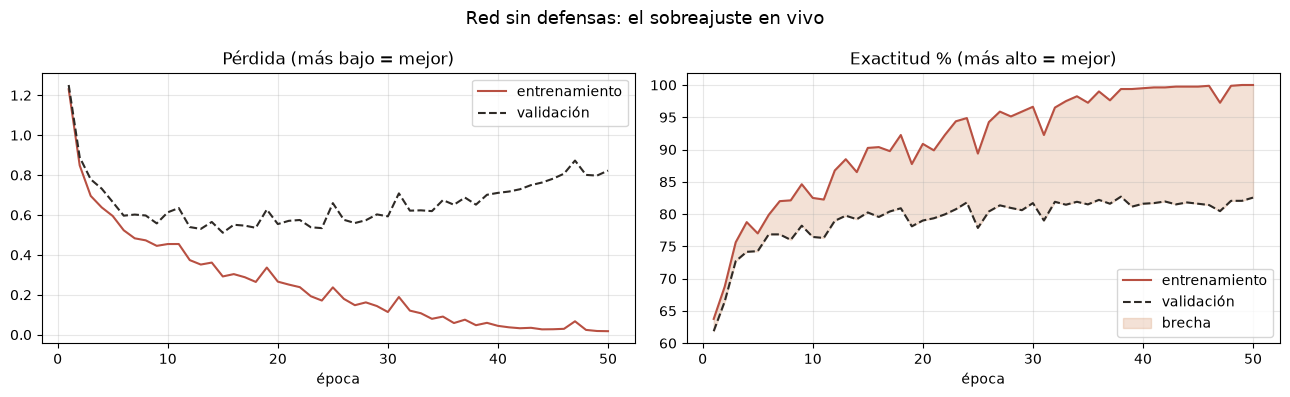

Al final: train 100.0% | validación 82.5% | brecha 17.4 puntos


In [12]:
curvas(hist_sd, "Red sin defensas: el sobreajuste en vivo")

**Léelo así.** En la derecha, la curva de **entrenamiento** sube hasta casi 100 %: la red ya se sabe las 800 fotos de memoria. La de **validación** se queda bastante más abajo y se aplana. El área sombreada entre las dos es la **brecha de generalización**, y es el síntoma principal del sobreajuste.

En la izquierda está la pista más clara. La pérdida de entrenamiento baja casi a cero, pero la de validación **toca fondo y después empieza a subir**. Desde ese punto, cada época extra empeora a la red frente a fotos nuevas: se vuelve cada vez más segura de respuestas que no siempre son correctas.

Busquemos el momento exacto en que la validación tocó fondo.

La pérdida de validación tocó fondo en la época 15: 0.511
Al final (época 50) había subido a 0.822
Desde la época 15, seguir entrenando solo sirvió para memorizar.


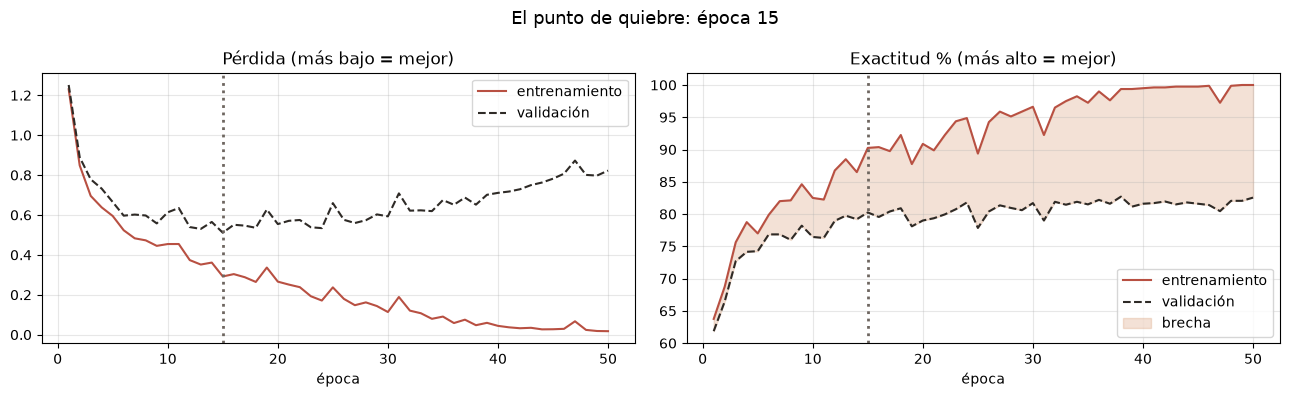

Al final: train 100.0% | validación 82.5% | brecha 17.4 puntos


In [13]:
mejor_ep_sd = int(np.argmin(hist_sd["val_loss"])) + 1        # la época con menor pérdida de validación
print(f"La pérdida de validación tocó fondo en la época {mejor_ep_sd}: "
      f"{hist_sd['val_loss'][mejor_ep_sd-1]:.3f}")
print(f"Al final (época {len(hist_sd['val_loss'])}) había subido a {hist_sd['val_loss'][-1]:.3f}")
print(f"Desde la época {mejor_ep_sd}, seguir entrenando solo sirvió para memorizar.")

curvas(hist_sd, f"El punto de quiebre: época {mejor_ep_sd}", marcar=mejor_ep_sd)

Ya tenemos el diagnóstico: **sobreajuste**, con nombre y apellido. Ahora el tratamiento, por tres frentes.

---

## Parte 6 — Cura 1, los datos: aumento de datos

La causa de fondo es que hay **pocos datos**. Lo ideal sería conseguir más fotos, pero en un proyecto real casi nunca se puede. El **aumento de datos** (*data augmentation*) es el truco: cada vez que la red ve una foto, se la mostramos un poco cambiada, al azar. Así nunca ve dos veces exactamente la misma imagen, y memorizar deja de servirle.

Usamos transformaciones suaves que **no cambian la clase**:

- **Volteo horizontal** (`RandomHorizontalFlip`): una camiseta en espejo sigue siendo una camiseta.
- **Desplazamiento** (`RandomAffine` con `translate`): la prenda puede estar un poco corrida, como en una foto real.

El aumento se aplica **solo al entrenamiento**. Validación y prueba quedan intactas, porque con ellas queremos medir la realidad, no una versión deformada.

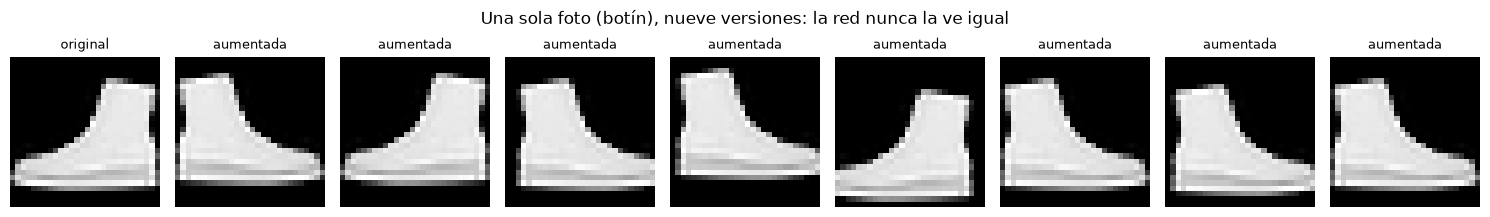

In [14]:
# La receta de aumento: se aplica al azar CADA vez que se pide una foto
tfm_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(),                         # volteo horizontal, al azar (50 %)
    transforms.RandomAffine(degrees=0, translate=(0.08, 0.08)), # corrimiento de hasta 8 % (unos 2 píxeles)
    transforms.ToTensor(),                                     # y al final, a tensor 0..1 como siempre
])

# El mismo dataset, pero con la receta de aumento. Usamos los MISMOS 800 índices.
train_aug_full = torchvision.datasets.FashionMNIST(root="./data", train=True, download=True, transform=tfm_aug)
train_aug = torch.utils.data.Subset(train_aug_full, idx_train)
train_loader_aug = torch.utils.data.DataLoader(train_aug, batch_size=BATCH, shuffle=True)

# Pedimos la MISMA foto ocho veces: cada vez sale distinta
foto = next(i for i in idx_train.tolist() if full_train.targets[i] == 9)   # un botín (clase 9): no es simétrico
fig, axs = plt.subplots(1, 9, figsize=(15, 2.2))
axs[0].imshow(full_train[foto][0][0], cmap="gray"); axs[0].set_title("original", fontsize=9)
for ax in axs[1:]:
    ax.imshow(train_aug_full[foto][0][0], cmap="gray")         # cada llamada aplica un cambio al azar
    ax.set_title("aumentada", fontsize=9)
for ax in axs: ax.axis("off")
plt.suptitle(f"Una sola foto ({CLASES[full_train.targets[foto]]}), nueve versiones: la red nunca la ve igual")
plt.tight_layout(); plt.show()

**El criterio que no se negocia: el aumento debe respetar la clase.** Mira qué pasa si aplicamos una transformación que no tiene sentido para ropa, como voltear de arriba abajo.

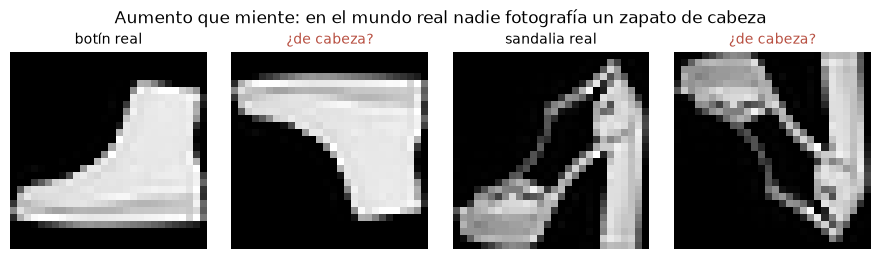

In [15]:
# Un aumento EQUIVOCADO: volteo vertical. Buscamos un botín (clase 9) y una sandalia (clase 5).
botin    = next(i for i in idx_train.tolist() if full_train.targets[i] == 9)
sandalia = next(i for i in idx_train.tolist() if full_train.targets[i] == 5)

fig, axs = plt.subplots(1, 4, figsize=(9, 2.6))
for k, (i, nombre) in enumerate([(botin, "botín"), (sandalia, "sandalia")]):
    img = full_train[i][0][0]
    axs[2*k].imshow(img, cmap="gray");                axs[2*k].set_title(f"{nombre} real", fontsize=10)
    axs[2*k+1].imshow(torch.flip(img, dims=[0]), cmap="gray")   # flip vertical = de cabeza
    axs[2*k+1].set_title("¿de cabeza?", fontsize=10, color="#B85042")
for ax in axs: ax.axis("off")
plt.suptitle("Aumento que miente: en el mundo real nadie fotografía un zapato de cabeza")
plt.tight_layout(); plt.show()

Un botín de cabeza no aparece en ninguna foto real. Si entrenamos con eso, le enseñamos a la red un mundo que no existe y le hacemos perder capacidad en cosas inútiles. Por eso usamos solo el volteo horizontal.

Ahora sí, entrenamos la misma red sin defensas, pero estudiando con fotos aumentadas.

Entrenando con AUMENTO DE DATOS...
  época   1 | train  58.4%  val  54.5%  | brecha  +3.9 pts | pérdida val 1.457
  época  10 | train  79.4%  val  75.2%  | brecha  +4.1 pts | pérdida val 0.669
  época  20 | train  84.1%  val  78.3%  | brecha  +5.8 pts | pérdida val 0.595
  época  30 | train  86.2%  val  79.4%  | brecha  +6.9 pts | pérdida val 0.593
  época  40 | train  89.8%  val  81.5%  | brecha  +8.3 pts | pérdida val 0.525
  época  50 | train  91.4%  val  80.4%  | brecha +11.0 pts | pérdida val 0.558
  época  60 | train  93.4%  val  81.8%  | brecha +11.6 pts | pérdida val 0.526
  época  70 | train  93.8%  val  82.0%  | brecha +11.8 pts | pérdida val 0.549
  época  80 | train  94.0%  val  82.1%  | brecha +11.9 pts | pérdida val 0.552
  época  90 | train  96.4%  val  83.0%  | brecha +13.4 pts | pérdida val 0.577
  época 100 | train  96.6%  val  83.0%  | brecha +13.6 pts | pérdida val 0.570
  Tiempo: 220 s


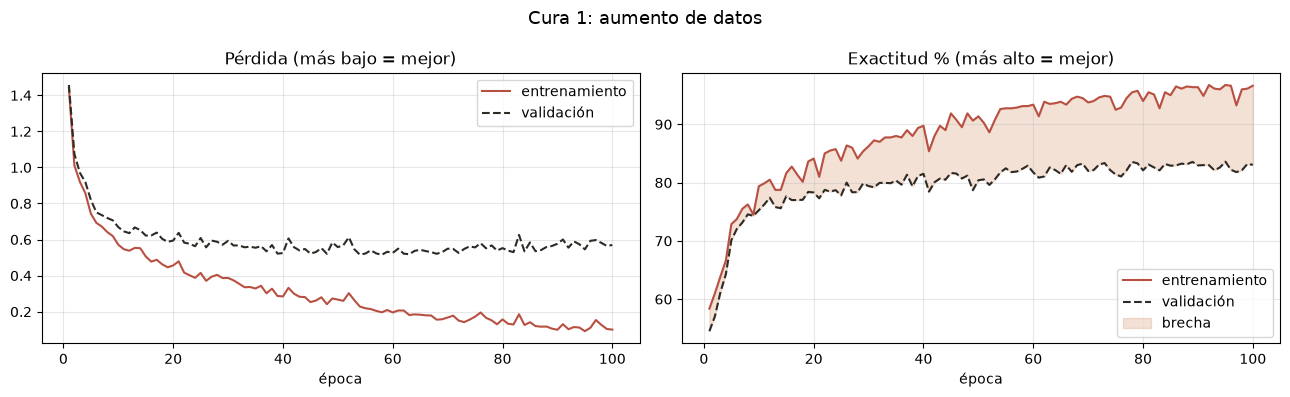

Al final: train 96.6% | validación 83.0% | brecha 13.6 puntos


In [16]:
torch.manual_seed(0)
modelo_aug = CNN(dropout=0.0)                       # la MISMA red, sin dropout
print("Entrenando con AUMENTO DE DATOS...")
hist_aug = entrenar(modelo_aug, train_loader_aug, epocas=100)   # cambia solo el loader de estudio
curvas(hist_aug, "Cura 1: aumento de datos")

**Léelo así.** La brecha crece mucho más despacio y la pérdida de validación ya no se dispara: memorizar le sirve menos, porque las fotos cambian en cada pasada. Fíjate en otra cosa: la curva de entrenamiento sube **más lento** y ya no llega a 100 %, porque le pusimos un problema más difícil. Por eso aquí entrenamos más épocas que antes: con aumento, la red necesita más tiempo para aprender.

---

## Parte 7 — Cura 2, el modelo: dropout y weight decay

El aumento atacó los datos. Ahora atacamos la **capacidad de memorizar** del modelo, con dos frenos clásicos:

- **Dropout.** Durante el entrenamiento, en cada paso apaga al azar una fracción de las neuronas de la capa oculta (aquí, el 30 %). Es como un equipo donde cada día falta gente distinta: nadie puede volverse imprescindible y todos tienen que saber un poco de todo. Al evaluar, `model.eval()` lo apaga y trabaja la red completa.
- **Weight decay** (regularización L2). Le suma a la pérdida un pequeño castigo por tener pesos grandes, así que la red prefiere soluciones con pesos pequeños. Pesos pequeños producen una función más suave, que no puede doblarse para pasar por cada foto como el polinomio de grado 7. Se activa con un solo argumento del optimizador.

Las defensas **se suman**: mantenemos el aumento y le agregamos los dos frenos.

### Por dentro del dropout: el dropout invertido

Antes de entrenar, una pregunta que vale la pena. Si al entrenar se apaga el 30 % de las neuronas y al evaluar trabajan todas, la capa siguiente recibiría de pronto más señal de la que está acostumbrada. ¿No se descalibra la red? Mira qué hace PyTorch con diez neuronas que valen 1.

In [17]:
capa = nn.Dropout(0.5)            # apaga cada neurona con probabilidad 0.5
x = torch.ones(10)                # diez neuronas que valen 1

capa.train()                      # modo entrenamiento
print("entrenando:", capa(x))     # ceros y DOSES: las que sobreviven se multiplican por 1/(1-0.5) = 2

capa.eval()                       # modo evaluación
print("evaluando: ", capa(x))     # todo en 1: no toca nada

capa3 = nn.Dropout(0.3)           # el 30 % que usamos hoy
capa3.train()
print("con p=0.3: ", capa3(x))    # las que sobreviven valen 1/0.7 = 1.43

entrenando: tensor([2., 2., 2., 0., 0., 2., 2., 2., 2., 2.])
evaluando:  tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])
con p=0.3:  tensor([0.0000, 1.4286, 1.4286, 1.4286, 1.4286, 1.4286, 0.0000, 1.4286, 1.4286,
        0.0000])


**Léelo así.** Al entrenar, las neuronas que sobreviven se multiplican por 1/(1 − p), así que **en promedio** la capa siguiente recibe la misma señal que con todas encendidas (con p = 0,5, la mitad vale 0 y la otra mitad vale 2: promedio 1). Por eso al evaluar no hay nada que corregir y `model.eval()` deja todo intacto.

Se llama **dropout invertido** porque el método original (Srivastava, Hinton y colegas, 2014) hacía la corrección al revés: al evaluar, multiplicando los pesos por (1 − p). Hacerla al entrenar deja el modelo listo para usarse, y por eso es lo que hace PyTorch. Si vuelves a correr la celda cambia cuáles se apagan, porque es azar, pero las que sobreviven siempre valen lo mismo.

Entrenando con AUMENTO + DROPOUT + WEIGHT DECAY...
  época   1 | train  57.2%  val  53.1%  | brecha  +4.1 pts | pérdida val 1.544
  época  10 | train  78.0%  val  74.8%  | brecha  +3.2 pts | pérdida val 0.662
  época  20 | train  81.5%  val  77.2%  | brecha  +4.2 pts | pérdida val 0.604
  época  30 | train  86.0%  val  79.3%  | brecha  +6.7 pts | pérdida val 0.569
  época  40 | train  88.4%  val  80.5%  | brecha  +7.8 pts | pérdida val 0.525
  época  50 | train  88.8%  val  81.0%  | brecha  +7.7 pts | pérdida val 0.534
  época  60 | train  91.8%  val  82.6%  | brecha  +9.2 pts | pérdida val 0.500
  época  70 | train  93.0%  val  82.4%  | brecha +10.6 pts | pérdida val 0.513
  época  80 | train  93.4%  val  81.5%  | brecha +11.8 pts | pérdida val 0.530
  época  90 | train  94.0%  val  83.0%  | brecha +10.9 pts | pérdida val 0.525
  época 100 | train  94.0%  val  82.7%  | brecha +11.3 pts | pérdida val 0.561
  Tiempo: 217 s


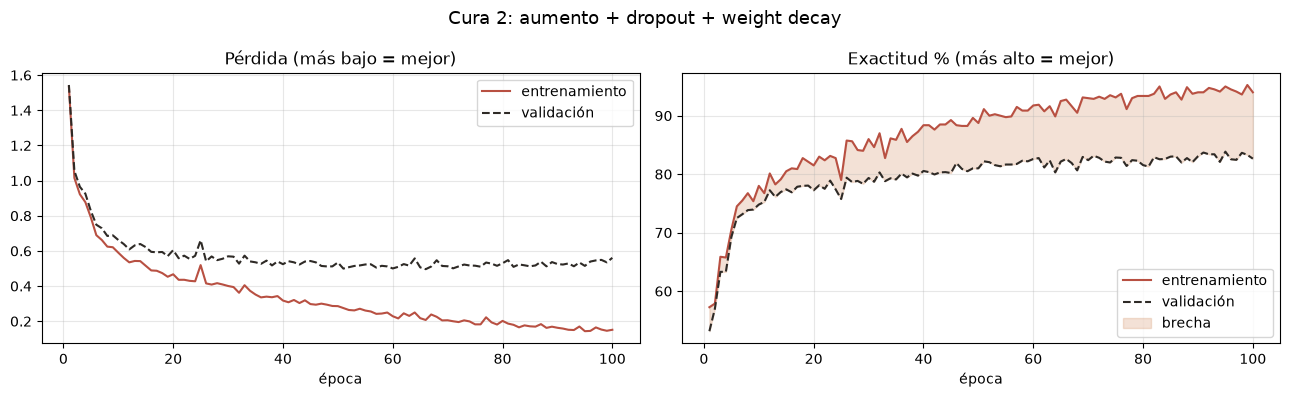

Al final: train 94.0% | validación 82.7% | brecha 11.3 puntos


In [18]:
torch.manual_seed(0)
modelo_reg = CNN(dropout=0.3)                    # freno 1: dropout dentro de la red
print("Entrenando con AUMENTO + DROPOUT + WEIGHT DECAY...")
hist_reg = entrenar(modelo_reg, train_loader_aug, epocas=100,
                    weight_decay=0.0001)               # freno 2: weight decay en el optimizador
curvas(hist_reg, "Cura 2: aumento + dropout + weight decay")

**Léelo así.** Las curvas de entrenamiento y validación van juntas buena parte del camino y después se separan despacio. Con 800 fotos siempre queda algo de brecha, pero es moderada y la pérdida de validación se mantiene baja. El modelo no impresiona en entrenamiento, pero lo que aprendió lo **generaliza**.

Un aviso importante: los frenos tienen dosis. Si exageras el dropout o el weight decay, la red ya no puede aprender ni lo básico y cae en **subajuste**, como la recta de la Parte 1. Lo probarás en la Parte 11.

---

## Parte 8 — Cura 3, el tiempo: early stopping

Queda un desperdicio. Entrenamos un número fijo de épocas aunque la validación haya dejado de mejorar mucho antes. El **early stopping** (parada temprana) vigila la pérdida de validación y hace dos cosas:

1. Cada vez que la validación **mejora**, guarda una copia de la red.
2. Si pasan `paciencia` épocas seguidas **sin mejorar**, detiene el entrenamiento y **recupera la mejor copia**.

Así no entrenas de más (sobreajuste) ni de menos. Le damos un techo alto de épocas y paciencia = 10; él decide cuándo parar.

Entrenando el MODELO FINAL: aumento + dropout + weight decay + early stopping...
  época   1 | train  57.2%  val  53.1%  | brecha  +4.1 pts | pérdida val 1.544
  época  10 | train  78.0%  val  74.8%  | brecha  +3.2 pts | pérdida val 0.662
  época  20 | train  81.5%  val  77.2%  | brecha  +4.2 pts | pérdida val 0.604
  época  30 | train  86.0%  val  79.3%  | brecha  +6.7 pts | pérdida val 0.569
  época  40 | train  88.4%  val  80.5%  | brecha  +7.8 pts | pérdida val 0.525
  época  50 | train  88.8%  val  81.0%  | brecha  +7.7 pts | pérdida val 0.534
  época  60 | train  91.8%  val  82.6%  | brecha  +9.2 pts | pérdida val 0.500
  -> Early stopping en la época 61: lleva 10 épocas sin mejorar.
  -> Recuperamos la red de la época 51, la mejor en validación.
  Tiempo: 127 s


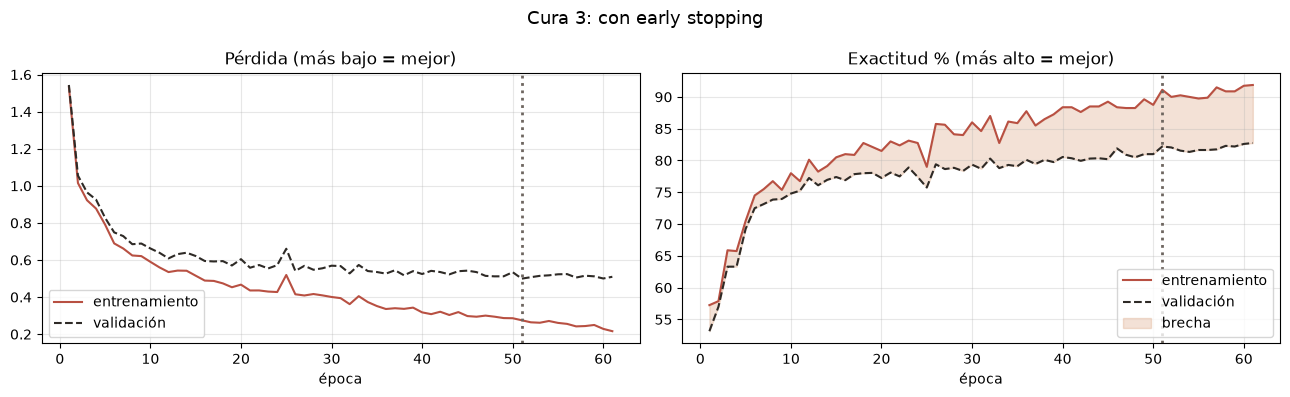

Al final: train 91.9% | validación 82.8% | brecha 9.1 puntos


In [19]:
torch.manual_seed(0)
modelo_final = CNN(dropout=0.3)
print("Entrenando el MODELO FINAL: aumento + dropout + weight decay + early stopping...")
hist_final = entrenar(modelo_final, train_loader_aug, epocas=150,
                      weight_decay=0.0001, paciencia=10)   # paciencia activa el early stopping
curvas(hist_final, "Cura 3: con early stopping", marcar=hist_final.get("mejor_epoca"))

La línea punteada vertical marca la época de la **mejor validación**: esa es la red que nos quedamos, aunque el entrenamiento haya seguido unas épocas más mientras se agotaba la paciencia.

El early stopping también habría salvado a la red sin defensas de la Parte 5: habría parado poco después de su punto de quiebre, antes de que la pérdida de validación se disparara.

---

## Parte 9 — El veredicto: los cuatro modelos frente al juez

Hasta ahora usamos la validación para tomar decisiones. Llegó el momento de mirar el **conjunto de prueba**, las 10 000 fotos que ninguna red vio y que no usamos para decidir nada. Es el único juez imparcial, y lo miramos **una sola vez**.

Para cada modelo medimos dos cosas: su exactitud en prueba, y su **brecha** (cuánto acierta en las fotos que estudió menos cuánto acierta en prueba).

Sin defensas       | train 100.0% | PRUEBA  82.0% | brecha  17.9 pts
+ Aumento          | train  96.6% | PRUEBA  83.1% | brecha  13.5 pts
+ Dropout y L2     | train  94.0% | PRUEBA  82.0% | brecha  12.0 pts
+ Early stopping   | train  91.1% | PRUEBA  80.8% | brecha  10.4 pts


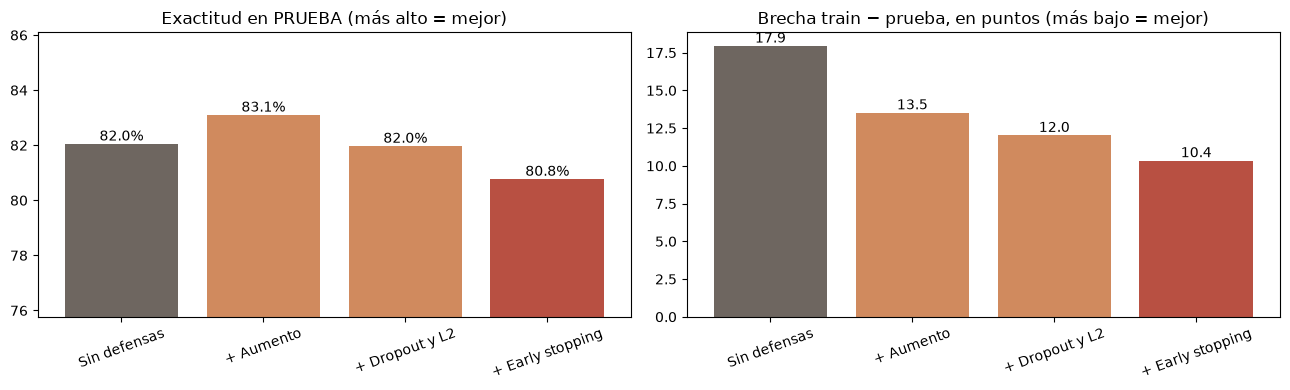

In [20]:
modelos = {                                       # los cuatro modelos, en el orden en que agregamos defensas
    "Sin defensas":          modelo_sd,
    "+ Aumento":             modelo_aug,
    "+ Dropout y L2":        modelo_reg,
    "+ Early stopping":      modelo_final,
}

nombres, acc_test, brechas = [], [], []
for nombre, m in modelos.items():
    _, a_train = evaluar(m, train_eval_loader)   # exactitud en las 800 que estudió
    _, a_test  = evaluar(m, test_loader)         # exactitud en las 10 000 de prueba
    nombres.append(nombre); acc_test.append(a_test * 100); brechas.append((a_train - a_test) * 100)
    print(f"{nombre:18s} | train {a_train*100:5.1f}% | PRUEBA {a_test*100:5.1f}% | brecha {(a_train-a_test)*100:5.1f} pts")

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4))
barras = a.bar(nombres, acc_test, color=["#6E6660", "#D08A5E", "#D08A5E", "#B85042"])
a.set_ylim(min(acc_test) - 5, max(acc_test) + 3)
a.set_title("Exactitud en PRUEBA (más alto = mejor)"); a.tick_params(axis="x", rotation=20)
a.bar_label(barras, fmt="%.1f%%")

barras = b.bar(nombres, brechas, color=["#6E6660", "#D08A5E", "#D08A5E", "#B85042"])
b.set_title("Brecha train − prueba, en puntos (más bajo = mejor)"); b.tick_params(axis="x", rotation=20)
b.bar_label(barras, fmt="%.1f")
plt.tight_layout(); plt.show()

**Léelo de izquierda a derecha**, que es el orden en que fuimos agregando defensas. La **brecha** cae casi a la mitad: la red sin defensas memorizó mucho más que las demás. La exactitud en prueba, en cambio, **apenas se mueve**: los modelos curados quedan por encima, pero por poco, y entre ellos las diferencias son del tamaño del ruido.

Esa es una lección honesta: la regularización hace **confiable** al modelo (lo que dice en entrenamiento se parece a lo que hará con fotos nuevas), pero **no puede inventar información** que 800 fotos no traen. Para subir mucho más la exactitud con pocos datos hace falta otra idea, y es justo la de la próxima clase.

### Otras defensas que vas a encontrar

Hoy practicamos las centrales. En artículos y proyectos aparecen también estas, y conviene reconocerlas:

| Frente | Técnica | Qué hace |
|---|---|---|
| Datos | **Cutout o random erasing** | Tapa un trozo de la foto al azar, como un dropout aplicado a la imagen |
| Datos | **Mixup** | Mezcla dos fotos y sus etiquetas en la misma proporción |
| Modelo | **Regularización L1** | Prima de la L2: lleva muchos pesos a cero exacto |
| Modelo | **Menos capacidad** | Menos filtros o capas: menos memoria para memorizar |
| Modelo | **Batch normalization** | Estabiliza el entrenamiento y regulariza un poco (la verás con ResNet en la Clase 9) |
| Entrenamiento | **Label smoothing** | No le pide 100 % de seguridad en la etiqueta correcta, así no aprende a ser arrogante |
| Entrenamiento | **Ensembles** | Entrena varias redes y promedia sus respuestas |
| Medición | **Validación cruzada k-fold** | No cura, pero mide mejor con pocos datos rotando qué parte hace de validación |

Y la más potente cuando hay pocos datos no está en esta tabla: partir de una red ya entrenada con millones de imágenes, el **transfer learning** de la Clase 8.

---

## Parte 10 — La matriz de confusión: no cuánto, sino dónde se equivoca

La exactitud es un solo número y esconde lo más útil: **qué confunde con qué**. La **matriz de confusión** lo muestra en una tabla de 10 × 10:

- cada **fila** es la clase **real** de la foto,
- cada **columna** es la clase que la red **predijo**,
- la **diagonal** son los aciertos,
- todo lo que está fuera de la diagonal son errores, y su patrón es el diagnóstico.

La calculamos para el modelo final sobre las 10 000 fotos de prueba.

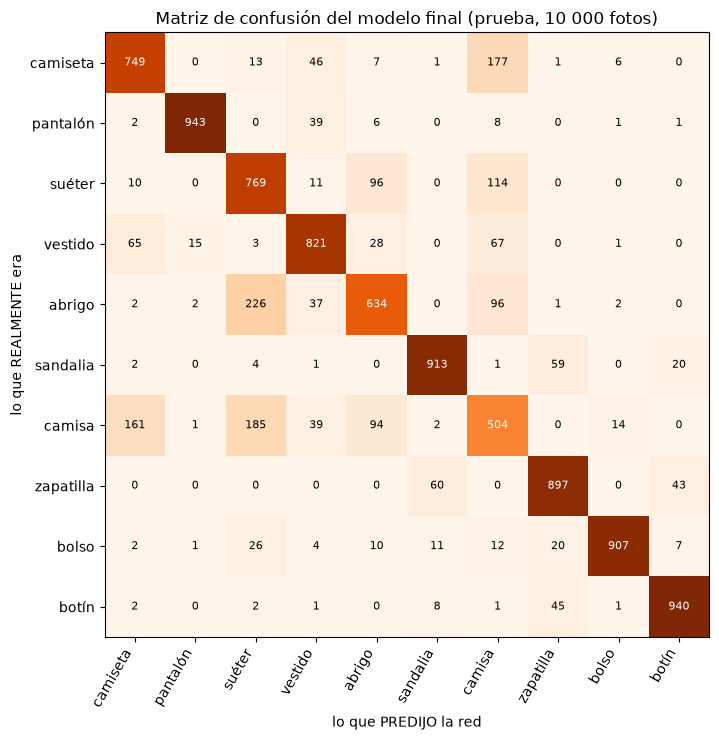

In [21]:
from sklearn.metrics import confusion_matrix      # scikit-learn ya viene en Colab

modelo_final.eval()
y_real, y_pred = [], []                           # aquí juntamos las respuestas de las 10 000 fotos
with torch.no_grad():
    for X, y in test_loader:
        pred = modelo_final(X.to(device)).argmax(1).cpu()   # la clase predicha para cada foto
        y_real.extend(y.tolist()); y_pred.extend(pred.tolist())
y_real, y_pred = np.array(y_real), np.array(y_pred)

cm = confusion_matrix(y_real, y_pred)             # la tabla 10x10 de conteos

fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(cm, cmap="Oranges")                # más oscuro = más fotos en esa celda
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels(CLASES, rotation=60, ha="right"); ax.set_yticklabels(CLASES)
ax.set_xlabel("lo que PREDIJO la red"); ax.set_ylabel("lo que REALMENTE era")
for i in range(10):                               # escribimos el número dentro de cada celda
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max() * 0.5 else "black")
ax.set_title("Matriz de confusión del modelo final (prueba, 10 000 fotos)")
plt.tight_layout(); plt.show()

Busca las celdas oscuras **fuera** de la diagonal. Ahora, dos preguntas concretas que la matriz responde: ¿qué clase le cuesta más a la red?, y ¿cuál es la confusión más frecuente?

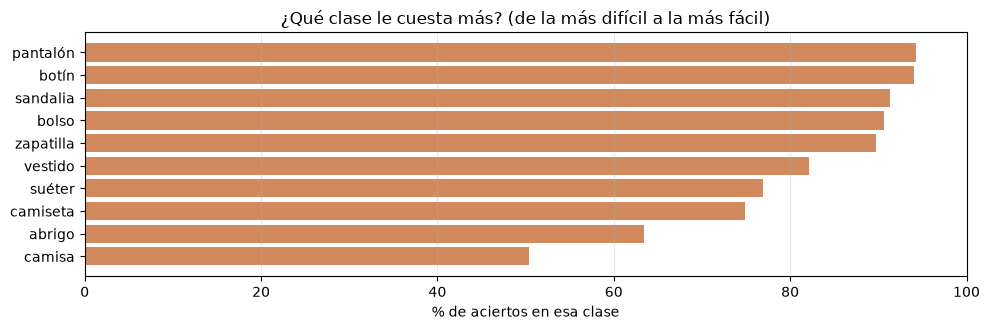

Confusión más frecuente: 'abrigo' tomado por 'suéter' (226 veces)


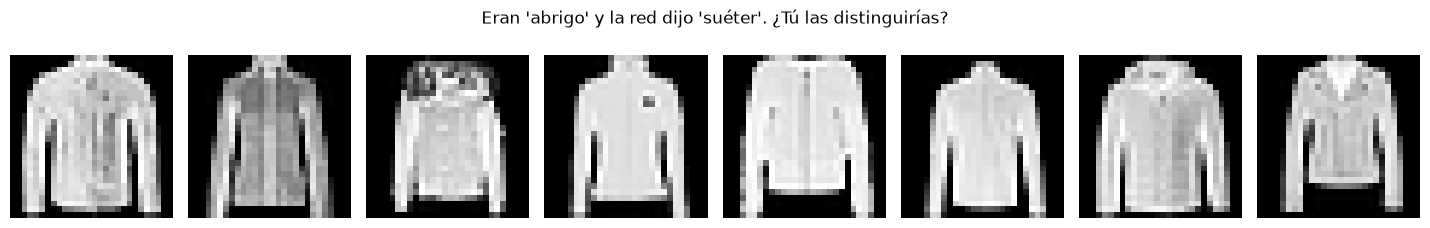

In [22]:
# 1) Aciertos por clase: la diagonal dividida por el total de cada fila
acierto_clase = cm.diagonal() / cm.sum(axis=1) * 100
orden = np.argsort(acierto_clase)                 # de la clase más difícil a la más fácil

plt.figure(figsize=(10, 3.4))
plt.barh([CLASES[i] for i in orden], acierto_clase[orden], color="#D08A5E")
plt.xlabel("% de aciertos en esa clase"); plt.title("¿Qué clase le cuesta más? (de la más difícil a la más fácil)")
plt.xlim(0, 100); plt.grid(axis="x", alpha=0.3); plt.tight_layout(); plt.show()

# 2) La confusión más frecuente: la celda más grande fuera de la diagonal
fuera = cm.copy(); np.fill_diagonal(fuera, 0)     # borramos los aciertos para mirar solo errores
r, p = np.unravel_index(fuera.argmax(), fuera.shape)
print(f"Confusión más frecuente: '{CLASES[r]}' tomado por '{CLASES[p]}' ({fuera[r, p]} veces)")

# Mostramos 8 de esas fotos: ¿tú las habrías acertado?
ejemplos = np.where((y_real == r) & (y_pred == p))[0][:8]
fig, axs = plt.subplots(1, len(ejemplos), figsize=(1.8 * len(ejemplos), 2.3))
for ax, i in zip(np.atleast_1d(axs), ejemplos):
    ax.imshow(test_data[i][0][0], cmap="gray"); ax.axis("off")
plt.suptitle(f"Eran '{CLASES[r]}' y la red dijo '{CLASES[p]}'. ¿Tú las distinguirías?")
plt.tight_layout(); plt.show()

**Léelo así.** Los errores no son al azar: casi siempre caen entre prendas de torso que en 28 × 28 píxeles grises se parecen muchísimo (**camisa**, camiseta, suéter, abrigo). La red casi nunca confunde un botín con un pantalón. Es una buena noticia, porque significa que aprendió formas reales; se equivoca donde una persona también dudaría.

Y es información accionable para un proyecto. Si tu modelo confunde siempre dos clases, la solución rara vez es una red más grande: suele ser **más ejemplos de esas dos clases**, mejor resolución o una característica que las distinga.

---

## Parte 11 — TU TURNO: mueve una palanca

Elige **una sola** palanca, cámbiala, vuelve a entrenar y compara las curvas y la brecha con lo que viste. Ideas:

- **Más datos.** Sube `N_TRAIN` a 4000 (Parte 2), vuelve a crear los loaders y entrena la red **sin defensas**. ¿Desaparece el sobreajuste solo con más datos?
- **Freno exagerado.** Entrena con `CNN(dropout=0.8)` y `weight_decay=5e-3`. ¿Ayuda o la red cae en subajuste?
- **Una sola familia de defensa.** Entrena con dropout y weight decay pero **sin** aumento (usa `train_loader`). ¿Qué pesa más aquí, defender los datos o el modelo?
- **Poca paciencia.** Repite el modelo final con `paciencia=2`. ¿Para demasiado pronto?

Entrenando con FRENO EXAGERADO (se aumento:  dropout 0.8 + weight decay 5e-3)...
  época   1 | train  43.5%  val  41.1%  | brecha  +2.4 pts | pérdida val 2.130
  época  10 | train  70.1%  val  67.0%  | brecha  +3.2 pts | pérdida val 0.851
  época  20 | train  74.4%  val  73.7%  | brecha  +0.7 pts | pérdida val 0.737
  época  30 | train  78.2%  val  75.8%  | brecha  +2.5 pts | pérdida val 0.672
  época  40 | train  77.9%  val  76.2%  | brecha  +1.7 pts | pérdida val 0.642
  época  50 | train  80.0%  val  76.6%  | brecha  +3.4 pts | pérdida val 0.616
  época  60 | train  79.9%  val  76.2%  | brecha  +3.6 pts | pérdida val 0.616
  época  70 | train  79.9%  val  76.1%  | brecha  +3.8 pts | pérdida val 0.606
  época  80 | train  81.9%  val  77.0%  | brecha  +4.8 pts | pérdida val 0.605
  época  90 | train  81.1%  val  77.3%  | brecha  +3.8 pts | pérdida val 0.593
  época 100 | train  82.2%  val  77.9%  | brecha  +4.3 pts | pérdida val 0.578
  Tiempo: 221 s


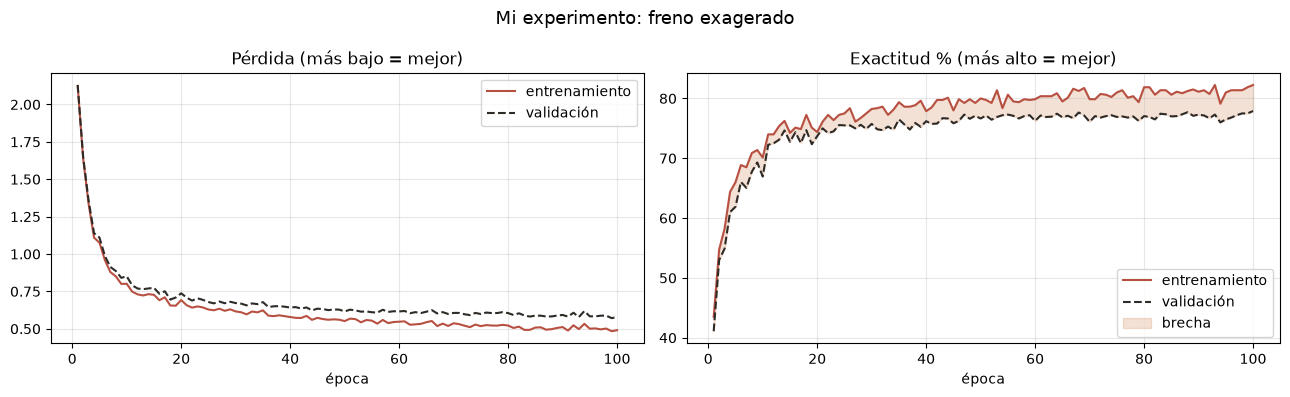

Al final: train 82.2% | validación 77.9% | brecha 4.3 puntos


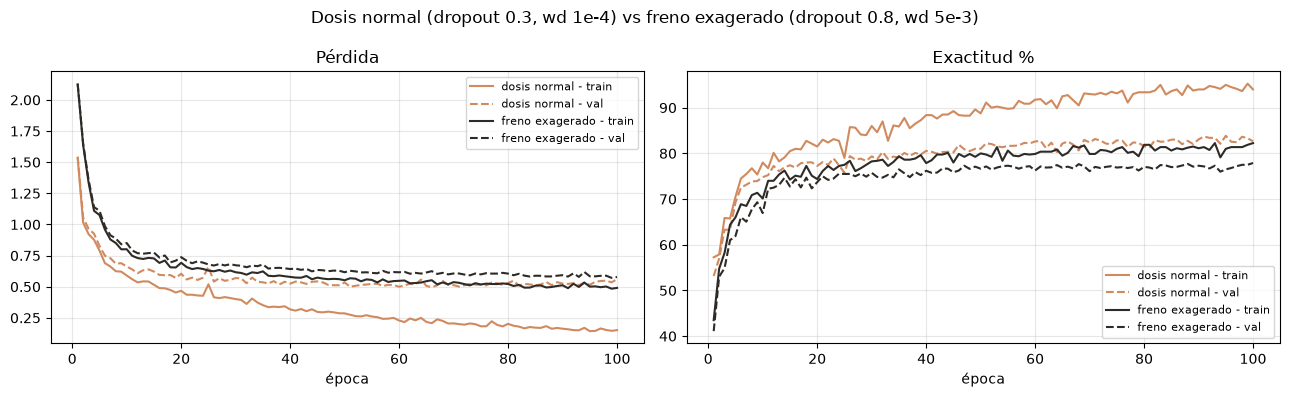

Dosis normal     | train  94.0% (pérdida 0.151) | val  82.7% | PRUEBA  82.0% | brecha train-val +11.3 pts
Freno exagerado  | train  82.2% (pérdida 0.491) | val  77.9% | PRUEBA  76.8% | brecha train-val  +4.3 pts


In [24]:
# ---------------------------------------------------------------
# FRENO EXAGERADO: dropout 0.8 y weight decay 5e-3
# ---------------------------------------------------------------
torch.manual_seed(0)                                   # misma red inicial que los demás
modelo_freno = CNN(dropout=0.8)                        # apaga el 80 % de la capa oculta
print("Entrenando con FRENO EXAGERADO (se aumento:  dropout 0.8 + weight decay 5e-3)...")
hist_freno = entrenar(modelo_freno, train_loader_aug, epocas=100,
                      weight_decay=5e-3)               # 50 veces más fuerte que en la Parte 7 (1e-4)
curvas(hist_freno, "Mi experimento: freno exagerado")

# --- Comparación directa con la dosis razonable de la Parte 7 (hist_reg) ---
ep_f = range(1, len(hist_freno["train_acc"]) + 1)
ep_r = range(1, len(hist_reg["train_acc"]) + 1)
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4))
a.plot(ep_r, hist_reg["train_loss"], color="#D08A5E", label="dosis normal - train")
a.plot(ep_r, hist_reg["val_loss"], "--", color="#D08A5E", label="dosis normal - val")
a.plot(ep_f, hist_freno["train_loss"], color="#2E2A26", label="freno exagerado - train")
a.plot(ep_f, hist_freno["val_loss"], "--", color="#2E2A26", label="freno exagerado - val")
a.set_title("Pérdida"); a.set_xlabel("época"); a.grid(alpha=0.3); a.legend(fontsize=8)
b.plot(ep_r, [v*100 for v in hist_reg["train_acc"]], color="#D08A5E", label="dosis normal - train")
b.plot(ep_r, [v*100 for v in hist_reg["val_acc"]], "--", color="#D08A5E", label="dosis normal - val")
b.plot(ep_f, [v*100 for v in hist_freno["train_acc"]], color="#2E2A26", label="freno exagerado - train")
b.plot(ep_f, [v*100 for v in hist_freno["val_acc"]], "--", color="#2E2A26", label="freno exagerado - val")
b.set_title("Exactitud %"); b.set_xlabel("época"); b.grid(alpha=0.3); b.legend(fontsize=8, loc="lower right")
fig.suptitle("Dosis normal (dropout 0.3, wd 1e-4) vs freno exagerado (dropout 0.8, wd 5e-3)")
plt.tight_layout(); plt.show()

# --- Veredicto con números, incluido el juez (prueba) ---
for nombre, m in [("Dosis normal", modelo_reg), ("Freno exagerado", modelo_freno)]:
    l_tr, a_tr = evaluar(m, train_eval_loader)
    l_va, a_va = evaluar(m, val_loader)
    _,    a_te = evaluar(m, test_loader)
    print(f"{nombre:16s} | train {a_tr*100:5.1f}% (pérdida {l_tr:.3f}) | val {a_va*100:5.1f}% "
          f"| PRUEBA {a_te*100:5.1f}% | brecha train-val {(a_tr-a_va)*100:+5.1f} pts")

**¿Ayuda o la red cae en subajuste?** Cae en sobreajuste, la brecha casi desaparece. Las curvas de entrenamiento y validación van pegadas, a veces con la de validación por encima. Así que el sobreajuste se cura, pero de más. En prueba sale igual o peor que el modelo de la Parte 7. Un freno más fuerte no gana nada.


### Pregunta escrita del laboratorio (para entregar)

**Mirando solo las curvas de entrenamiento y validación, ¿cómo distingues un modelo que sobreajusta de uno que subajusta? Nombra una técnica que ataque el sobreajuste por el lado de los datos y otra por el lado del modelo, y explica en una frase por qué cada una funciona.**

*(Responde en cuatro a seis líneas en la celda de abajo.)*

*Un modelo que sobreajusta muestra una brecha grande entre las curvas, Un modelo que subajusta tiene las dos curvas juntas pero ambas malas, por el lado de los datos podria ser el aumento de datos, funciona porque la red nunca ve dos veces la misma imagen, por el lado del modelo podria ser el dropout porque al apagarse neuronas al azar en cada paso ninguna puede volverse imprescindible ni guardar detalles de fotos concretas, y la red se vera obligada a aprender rasgos más generales.* 

---

## Cierre

Hoy no aprendiste una arquitectura nueva: aprendiste a **hacer confiable cualquier arquitectura**. Viste el sobreajuste primero con 8 puntos y después con una CNN de verdad, aprendiste a reconocerlo en la **brecha** entre las curvas y en la pérdida de validación que sube, y lo curaste por tres frentes: los **datos** (aumento), el **modelo** (dropout y weight decay) y el **tiempo** (early stopping). Por último evaluaste de verdad, con un juez que se mira una sola vez y una matriz que dice dónde falla la red.

**Puente a la Clase 8.** La regularización cerró la brecha, pero la exactitud quedó con un techo, porque 800 fotos no traen más información. ¿Y si en vez de partir de cero partimos de una red que **ya vio millones de imágenes**? Esa es la idea del **transfer learning**: tomar prestado lo que otra red ya aprendió y adaptarlo a nuestro problema.